1. IMPORT LIBRARIES

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.applications import ResNet50
from sklearn.model_selection import train_test_split

c:\Users\BLESSED-PC\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.3) or chardet (7.3.0)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(


2. IMAGE PATHS AND LABELS

In [2]:
styles = pd.read_csv("../data/styles.csv", on_bad_lines="skip")

id_to_category = dict(
    zip(styles["id"], styles["masterCategory"])
)

image_paths = []
labels = []

for file in os.listdir("../data/images"):

    file_id = int(file.split(".")[0])

    if file_id in id_to_category:
        image_paths.append(
            os.path.join("../data/images", file)
        )
        labels.append(id_to_category[file_id])

3. CONVERT CATEGORY NAME TO NUMBERS

In [3]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

labels = encoder.fit_transform(labels)

print(encoder.classes_)

['Accessories' 'Apparel' 'Footwear' 'Free Items' 'Home' 'Personal Care'
 'Sporting Goods']


4. SPLIT DATASET

In [5]:
train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
)

5. IMAGE LOADING FUNCTION

In [ ]:
def load_image(path, label):

    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(image, (224, 224))

    image = preprocess_input(image)

    return image, label

6. DATASET

In [ ]:
batch_size = 32

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE #automatically use multiple CPU workers to run load_image() concurrently.
)

train_ds = train_ds.shuffle(1000)
train_ds = train_ds.batch(batch_size)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

In [8]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(batch_size)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

7. BUILD MODEL

In [9]:
num_classes = len(encoder.classes_)

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

8. TRAIN MODEL

In [10]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=10
)

Epoch 1/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4389s 4s/step - accuracy: 0.9726 - loss: 0.1017 - val_accuracy: 0.9848 - val_loss: 0.0602
Epoch 2/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4498s 4s/step - accuracy: 0.9853 - loss: 0.0560 - val_accuracy: 0.9866 - val_loss: 0.0560
Epoch 3/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4578s 4s/step - accuracy: 0.9887 - loss: 0.0435 - val_accuracy: 0.9866 - val_loss: 0.0584
Epoch 4/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4409s 4s/step - accuracy: 0.9902 - loss: 0.0369 - val_accuracy: 0.9865 - val_loss: 0.0695
Epoch 5/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4444s 4s/step - accuracy: 0.9905 - loss: 0.0368 - val_accuracy: 0.9865 - val_loss: 0.0592
Epoch 6/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4267s 4s/step - accuracy: 0.9930 - loss: 0.0269 - val_accuracy: 0.9889 - val_loss: 0.0540
Epoch 7/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 5617s 5s/step - accuracy: 0.9929 - loss: 0.0275 - val_accuracy: 0.9863 - val_loss: 0.0679
Epoch 8/10
1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4743s 4s/step - accuracy: 0.9926 -

In [11]:
model.save("fashion_model.keras")

SIMILARITY

In [12]:
X_features = model.predict(train_ds)

1111/1111 ━━━━━━━━━━━━━━━━━━━━ 3859s 3s/step


In [41]:
feature_model = tf.keras.Sequential(
    model.layers[:-3]
)

In [42]:
feature_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [43]:
features = feature_model.predict(train_ds)

1111/1111 ━━━━━━━━━━━━━━━━━━━━ 4073s 4s/step


In [44]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors(n_neighbors=5, metric="euclidean")

knn.fit(features)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None


In [45]:
features[0].shape

(2048,)

In [46]:
test_img = tf.io.read_file('test.jpg')
test_img = tf.image.decode_jpeg(test_img, channels=3)
test_img = tf.image.resize(test_img, (224, 224))
test_img = preprocess_input(test_img)

In [47]:
test_img = np.expand_dims(test_img, axis=0)

In [48]:
distances, indices = knn.kneighbors(feature_model.predict(test_img))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [49]:
distances

array([[6.55594704e-05, 1.56419983e+01, 1.69226856e+01, 1.85439529e+01,
        1.93197918e+01]])

In [50]:
indices

array([[ 3720,  2008, 28068, 23114, 19595]])

In [51]:
import matplotlib.pyplot as plt

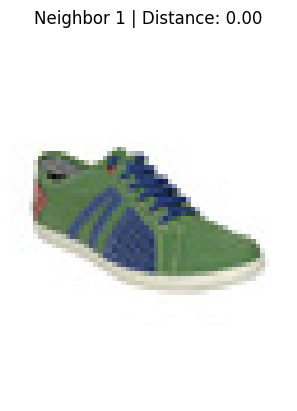

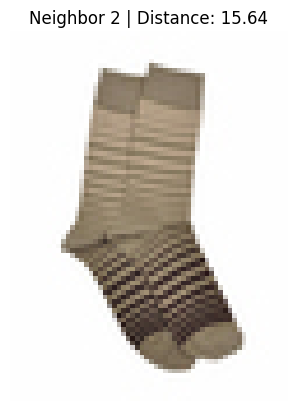

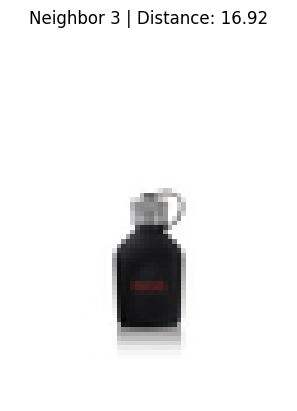

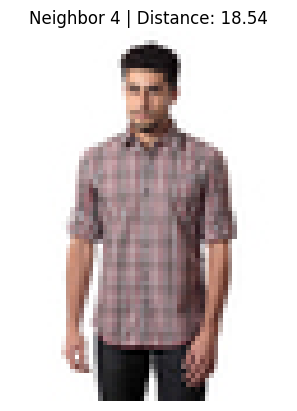

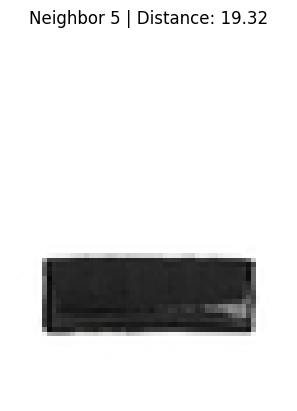

In [52]:
import matplotlib.pyplot as plt
import cv2

for i, idx in enumerate(indices[0]):

    img = cv2.imread(image_paths[idx])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure()
    plt.imshow(img)
    plt.title(f"Neighbor {i+1} | Distance: {distances[0][i]:.2f}")
    plt.axis("off")
    plt.show()

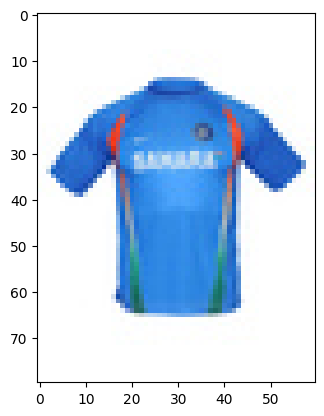

In [53]:
plt.imshow(cv2.cvtColor(cv2.imread('test.jpg'), cv2.COLOR_BGR2RGB))